Зниження розмірності, кластеризація та класифікація текстових даних

Мета роботи: Ознайомитися з базовими методами навчання без учителя та обробки текстових даних: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів з використанням бібліотеки Scikit-learn.  


Завдання 1: Зниження розмірності та візуалізація даних

Візьміть датасет, з яким ви працювали в лабораторній роботі №1.
Застосуйте `sklearn.decomposition.PCA` для зниження розмірності даних. На отриманих даних навчіть один з алгоритмів класифікації з Lab 1 та порівняйте результати класифікації "до" та "після" PCA.
Зробіть висновки: як PCA вплинув на якість класифікації;  наскільки вдалося зменшити кількість ознак;  чи змінився час навчання моделі.
Для того самого датасету застосуйте `sklearn.manifold.TSNE` для зниження розмірності до 2D. Візуалізуйте отримані дані, використовуючи кольори для позначення класів, та поясніть результат.

Імпорт бібліотек і даних: Використано той самий датасет `cyber_attack_dataset_100000.csv` із 100 000 записів мережевих подій. Ознаки: `duration`, `src_bytes`, `dst_bytes`, `packet_count`, `protocol`, `failed_logins`; цільова змінна: `attack_type`.

In [1]:
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from wordcloud import WordCloud
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, silhouette_score,
    adjusted_rand_score, normalized_mutual_info_score
)

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25

DATA_PATH = Path('cyber_attack_dataset_100000.csv')

df = pd.read_csv(DATA_PATH)
print(f'Розмір датасету: {df.shape[0]:,} рядків × {df.shape[1]} стовпців')
display(df.head())

Розмір датасету: 100,000 рядків × 7 стовпців


,duration,src_bytes,dst_bytes,packet_count,protocol,failed_logins,attack_type
0,1,8605,418,631,TCP,0,DDoS
1,1,499,148,131,UDP,0,PortScan
2,10,370,160,105,UDP,0,PortScan
3,2,5138,320,666,TCP,0,DDoS
4,36,524,467,58,UDP,10,BruteForce


Назви колонок: ['duration', 'src_bytes', 'dst_bytes', 'packet_count', 'protocol', 'failed_logins', 'attack_type']

Типи даних:


,dtype
duration,int64
src_bytes,int64
dst_bytes,int64
packet_count,int64
protocol,object
failed_logins,int64
attack_type,object



Пропущені значення:


,missing
duration,0
src_bytes,0
dst_bytes,0
packet_count,0
protocol,0
failed_logins,0
attack_type,0



Розподіл класів:


,count
attack_type,
BruteForce,25039
DDoS,25077
Normal,24876
PortScan,25008


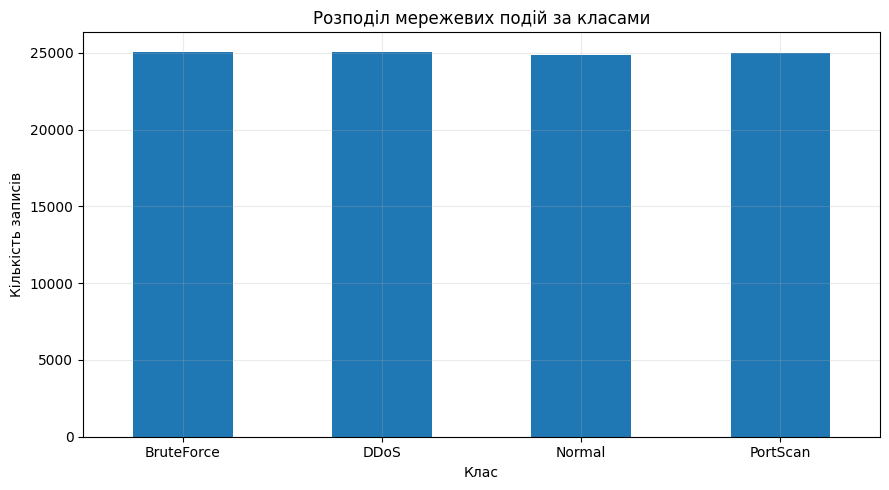

Ознаки: ['duration', 'src_bytes', 'dst_bytes', 'packet_count', 'protocol', 'failed_logins']
Числові ознаки: ['duration', 'src_bytes', 'dst_bytes', 'packet_count', 'failed_logins']
Категоріальні ознаки: ['protocol']
Цільова змінна: attack_type


In [2]:
print('Назви колонок:', df.columns.tolist())
print('\nТипи даних:')
display(df.dtypes.rename('dtype').to_frame())
print('\nПропущені значення:')
display(df.isna().sum().rename('missing').to_frame())
print('\nРозподіл класів:')
class_counts = df['attack_type'].value_counts().sort_index()
display(class_counts.rename('count').to_frame())

ax = class_counts.plot(kind='bar', title='Розподіл мережевих подій за класами',
                       xlabel='Клас', ylabel='Кількість записів', rot=0)
plt.tight_layout()
plt.show()

TARGET = 'attack_type'
X = df.drop(columns=TARGET)
y = df[TARGET]
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print('Ознаки:', X.columns.tolist())
print('Числові ознаки:', num_cols)
print('Категоріальні ознаки:', cat_cols)
print('Цільова змінна:', TARGET)

Зниження розмірності за допомогою PCA:
PCA (Principal Component Analysis) перетворює початкові ознаки на нові некорельовані компоненти, впорядковані за часткою поясненої дисперсії. Перед PCA числові ознаки стандартизуються, а `protocol` кодується методом One-Hot Encoding. Масштабування важливе, оскільки ознаки мають різні одиниці та діапазони значень.
Для коректного порівняння спочатку виконується train/test split. `preprocessor` навчається лише на training-вибірці. Для класифікації використовується Decision Tree з `max_depth=6` — один з алгоритмів  Lab 1. Модель навчається на початковому наборі ознак і на PCA-представленні.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ],
    verbose_feature_names_out=False
)

prep_start = time.perf_counter()
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)
preprocessing_time = time.perf_counter() - prep_start
feature_names = preprocessor.get_feature_names_out()

print('Кількість ознак після кодування:', X_train_scaled.shape[1])
print('Ознаки після preprocessing:', list(feature_names))
print(f'Час підготовки train/test: {preprocessing_time:.4f} с')

Кількість ознак після кодування: 7
Ознаки після preprocessing: ['duration', 'src_bytes', 'dst_bytes', 'packet_count', 'failed_logins', 'protocol_TCP', 'protocol_UDP']
Час підготовки train/test: 0.0422 с


Параметр `n_components=0.95` означає, що кількість головних компонент буде вибрана автоматично так, щоб сумарно зберігалося щонайменше 95% дисперсії навчальних даних.

Ознак до PCA: 7
Головних компонент після PCA: 5
Скорочення кількості вимірів: 28.6%
Сумарна пояснена дисперсія: 0.9587 (95.87%)
Час fit_transform/transform PCA: 0.0326 с


,Компонента,Пояснена дисперсія,Накопичена дисперсія
0,PC1,0.471705,0.471705
1,PC2,0.243007,0.714712
2,PC3,0.133283,0.847995
3,PC4,0.062619,0.910614
4,PC5,0.048082,0.958696


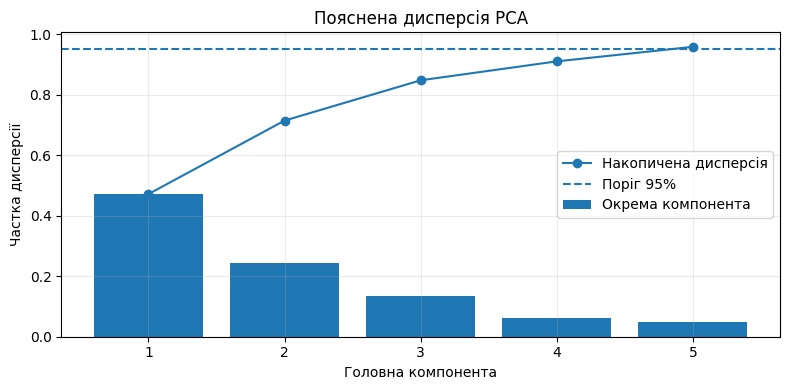

In [4]:
pca = PCA(n_components=0.95, svd_solver='full', random_state=RANDOM_STATE)
pca_start = time.perf_counter()
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)
pca_transform_time = time.perf_counter() - pca_start

n_before = X_train_scaled.shape[1]
n_after = X_train_pca.shape[1]
reduction_pct = (1 - n_after / n_before) * 100
explained_total = pca.explained_variance_ratio_.sum()

print(f'Ознак до PCA: {n_before}')
print(f'Головних компонент після PCA: {n_after}')
print(f'Скорочення кількості вимірів: {reduction_pct:.1f}%')
print(f'Сумарна пояснена дисперсія: {explained_total:.4f} ({explained_total*100:.2f}%)')
print(f'Час fit_transform/transform PCA: {pca_transform_time:.4f} с')

display(pd.DataFrame({
    'Компонента': [f'PC{i+1}' for i in range(n_after)],
    'Пояснена дисперсія': pca.explained_variance_ratio_,
    'Накопичена дисперсія': np.cumsum(pca.explained_variance_ratio_)
}))

plt.figure(figsize=(8, 4))
plt.bar(range(1, n_after + 1), pca.explained_variance_ratio_, label='Окрема компонента')
plt.plot(range(1, n_after + 1), np.cumsum(pca.explained_variance_ratio_),
         marker='o', label='Накопичена дисперсія')
plt.axhline(0.95, linestyle='--', label='Поріг 95%')
plt.xticks(range(1, n_after + 1))
plt.xlabel('Головна компонента')
plt.ylabel('Частка дисперсії')
plt.title('Пояснена дисперсія PCA')
plt.legend()
plt.tight_layout()
plt.show()

Порівняння класифікації до та після PCA.
Оцінюється Accuracy та macro F1, також фіксується час навчання класифікатора (`fit`).

,Представлення,Кількість ознак,Accuracy,Macro F1,"Час навчання, с"
0,Початкові ознаки,7,0.99980,0.999800,0.145954
1,Після PCA,5,0.99835,0.998346,0.354379


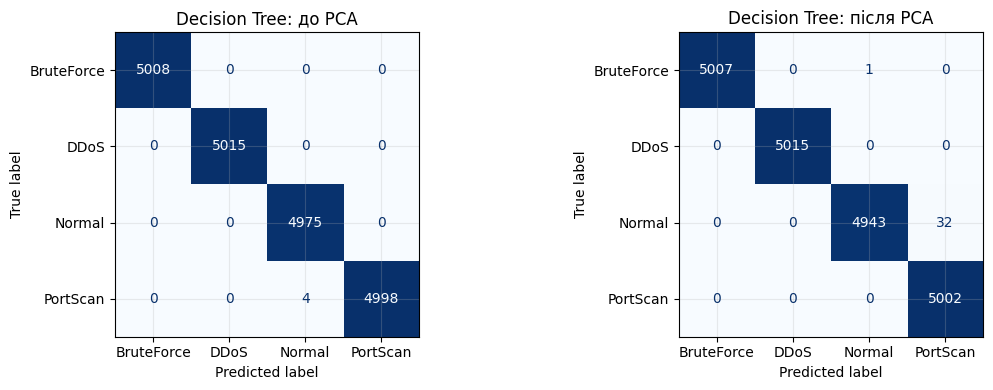

Classification report — початкові ознаки:
              precision    recall  f1-score   support

  BruteForce       1.00      1.00      1.00      5008
        DDoS       1.00      1.00      1.00      5015
      Normal       1.00      1.00      1.00      4975
    PortScan       1.00      1.00      1.00      5002

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000

Classification report — після PCA:
              precision    recall  f1-score   support

  BruteForce       1.00      1.00      1.00      5008
        DDoS       1.00      1.00      1.00      5015
      Normal       1.00      0.99      1.00      4975
    PortScan       0.99      1.00      1.00      5002

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



In [5]:
tree_before = DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE)
start = time.perf_counter()
tree_before.fit(X_train_scaled, y_train)
time_before = time.perf_counter() - start
pred_before = tree_before.predict(X_test_scaled)

tree_after = DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE)
start = time.perf_counter()
tree_after.fit(X_train_pca, y_train)
time_after = time.perf_counter() - start
pred_after = tree_after.predict(X_test_pca)

comparison = pd.DataFrame([
    {
        'Представлення': 'Початкові ознаки',
        'Кількість ознак': n_before,
        'Accuracy': accuracy_score(y_test, pred_before),
        'Macro F1': f1_score(y_test, pred_before, average='macro'),
        'Час навчання, с': time_before
    },
    {
        'Представлення': 'Після PCA',
        'Кількість ознак': n_after,
        'Accuracy': accuracy_score(y_test, pred_after),
        'Macro F1': f1_score(y_test, pred_after, average='macro'),
        'Час навчання, с': time_after
    }
])
display(comparison.round(6))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, pred, title in zip(
    axes,
    [pred_before, pred_after],
    ['Decision Tree: до PCA', 'Decision Tree: після PCA']
):
    cm = confusion_matrix(y_test, pred, labels=sorted(y.unique()))
    ConfusionMatrixDisplay(cm, display_labels=sorted(y.unique())).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d'
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

print('Classification report — початкові ознаки:')
print(classification_report(y_test, pred_before, zero_division=0))
print('Classification report — після PCA:')
print(classification_report(y_test, pred_after, zero_division=0))

Висновок:
PCA зменшив кількість ознак із 7 до 5 (скорочення на 28,6%) і зберіг 95,87% сумарної дисперсії. Accuracy Decision Tree зменшилася з 0,99980 до 0,99835, тобто лише на 0,145%; Macro F1 змінився аналогічно. Отже, майже всю класифікаційну якість вдалося зберегти при меншій кількості вимірів.
Час навчання дерева в цьому запуску становив приблизно 0,149 с до PCA та 0,347 с після PCA. Тобто скорочення кількості компонент не прискорило саме навчання дерева. PCA створює нові лінійні комбінації початкових ознак, через що дерево втрачає прості порогові розбиття за первинними полями. 

Візуалізація даних за допомогою t-SNE:
`t-SNE` — нелінійний метод зниження розмірності, який намагається зберігати локальні сусідства об'єктів. Для візуалізації використовується 2D-представлення. Через обчислювальну вартість t-SNE застосовується до стратифікованої вибірки по 600 об'єктів кожного класу (усього 2 400 записів), кольори позначають справжні класи.

t-SNE побудовано для 2,400 об’єктів за 4.39 с


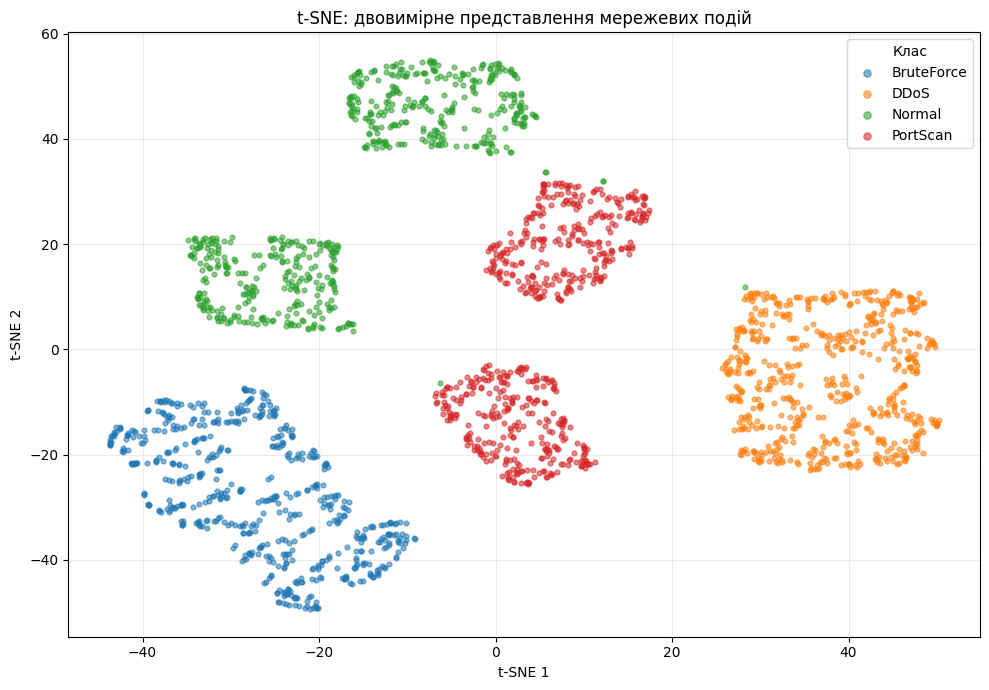

In [6]:
# Для t-SNE використовуємо незалежно масштабовані ознаки, без target.
X_all_scaled = preprocessor.fit_transform(X)

# Стратифікований піднабір: однакова кількість прикладів кожного класу.
tsne_sample = df.groupby('attack_type', group_keys=False).sample(
    n=600, random_state=RANDOM_STATE
).sort_index()
X_tsne_input = X_all_scaled[tsne_sample.index]
y_tsne = tsne_sample['attack_type'].reset_index(drop=True)

start = time.perf_counter()
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    max_iter=750,
    random_state=RANDOM_STATE
)
X_tsne_2d = tsne.fit_transform(X_tsne_input)
tsne_time = time.perf_counter() - start
print(f't-SNE побудовано для {len(tsne_sample):,} об’єктів за {tsne_time:.2f} с')

tsne_plot = pd.DataFrame({
    't-SNE 1': X_tsne_2d[:, 0],
    't-SNE 2': X_tsne_2d[:, 1],
    'Клас': y_tsne
})
plt.figure(figsize=(10, 7))
for label in sorted(tsne_plot['Клас'].unique()):
    part = tsne_plot[tsne_plot['Клас'] == label]
    plt.scatter(part['t-SNE 1'], part['t-SNE 2'], s=12, alpha=0.55, label=label)
plt.title('t-SNE: двовимірне представлення мережевих подій')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend(title='Клас', markerscale=1.5)
plt.tight_layout()
plt.show()

t-SNE є нелінійним методом зниження розмірності, що відображає локальну структуру багатовимірних даних. На проекції видно утворення окремих згустків. Клас `BruteForce` утворює окреме чітке скупчення через унікальний показник failed_logins. Клас `Normal` має спільні області перекриття з класами `DDoS` та `PortScan`.

Завдання 2: Кластерний аналіз за допомогою K-Means

На цьому етапі цільова змінна `attack_type` не використовується під час навчання кластеризатора. Для K-Means беруться лише масштабовані ознаки мережевого потоку. Категоріальна ознака `protocol` попередньо закодована One-Hot Encoding.

Доцільну кількість кластерів оцінюємо за двома підходами:
- Elbow Method: шукаємо ділянку графіка інерції, після якої її зменшення стає менш різким.
- Silhouette Score: більше значення означає кращу компактність кластерів та їх відокремленість.

Для швидкого порівняння k використовується випадкова підвибірка 10 000 записів; фінальна модель з обраним k навчається на всіх 100 000 записах.

k=2: inertia=35414.9, silhouette=0.3781
k=3: inertia=24008.0, silhouette=0.4094
k=4: inertia=15047.7, silhouette=0.4682
k=5: inertia=12903.9, silhouette=0.4556
k=6: inertia=11010.0, silhouette=0.4367
k=7: inertia=9469.7, silhouette=0.4273
k=8: inertia=8386.6, silhouette=0.4316


,Кількість кластерів k,Inertia,Silhouette Score
0,2,35414.9127,0.3781
1,3,24007.9516,0.4094
2,4,15047.6707,0.4682
3,5,12903.8898,0.4556
4,6,11009.9510,0.4367
5,7,9469.7415,0.4273
6,8,8386.6377,0.4316


Найвище значення Silhouette Score отримано при k=4.


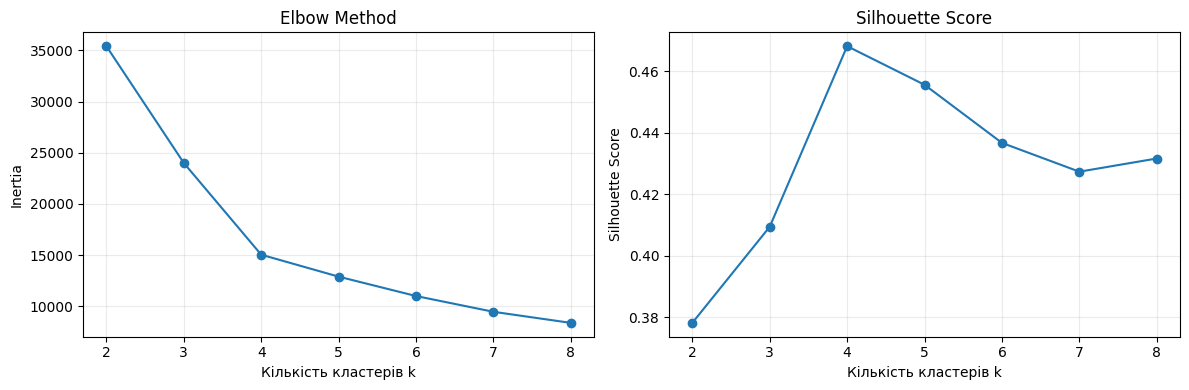

In [7]:
# Важливо: у X_cluster немає target.
X_cluster = X_all_scaled
assert TARGET not in X.columns

rng = np.random.RandomState(RANDOM_STATE)
cluster_sample_idx = rng.choice(len(X_cluster), size=10_000, replace=False)
X_cluster_sample = X_cluster[cluster_sample_idx]

k_values = range(2, 9)
inertias = []
silhouette_values = []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    sample_labels = km.fit_predict(X_cluster_sample)
    inertias.append(km.inertia_)
    sil = silhouette_score(
        X_cluster_sample, sample_labels,
        sample_size=2500, random_state=RANDOM_STATE
    )
    silhouette_values.append(sil)
    print(f'k={k}: inertia={km.inertia_:.1f}, silhouette={sil:.4f}')

k_results = pd.DataFrame({
    'Кількість кластерів k': list(k_values),
    'Inertia': inertias,
    'Silhouette Score': silhouette_values
})
display(k_results.round(4))

best_k = int(k_results.loc[k_results['Silhouette Score'].idxmax(), 'Кількість кластерів k'])
print(f'Найвище значення Silhouette Score отримано при k={best_k}.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Кількість кластерів k')
axes[0].set_ylabel('Inertia')
axes[1].plot(list(k_values), silhouette_values, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Кількість кластерів k')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

Обираємо `k`, яке має найвище Silhouette Score на перевіреному діапазоні. Далі K-Means навчається на повному наборі ознак. Для візуалізації використовується PCA з двома компонентами. PCA тут лише зменшує розмірність для графіка: сам K-Means виконується у повному масштабованому просторі ознак.

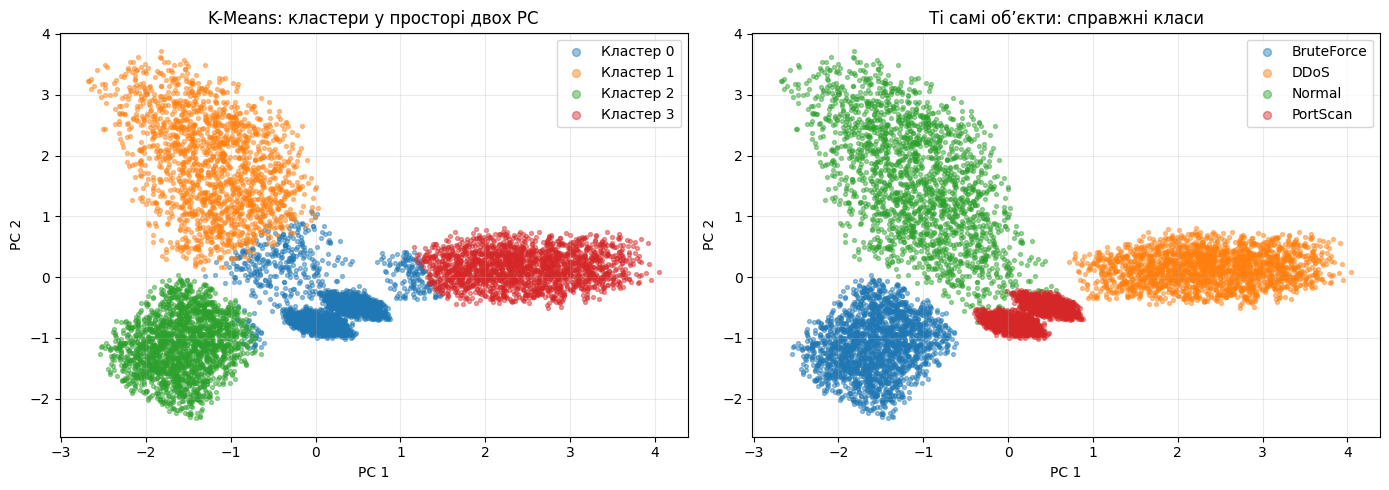

Фінальний Silhouette Score (оцінка на підвибірці): 0.4673
Adjusted Rand Index (ARI): 0.8410
Normalized Mutual Information (NMI): 0.8551


In [8]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE)
cluster_labels = kmeans.fit_predict(X_cluster)

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_cluster_2d = pca_2d.fit_transform(X_cluster)

plot_idx = rng.choice(len(df), size=8000, replace=False)
cluster_vis = pd.DataFrame({
    'PC 1': X_cluster_2d[plot_idx, 0],
    'PC 2': X_cluster_2d[plot_idx, 1],
    'Кластер': cluster_labels[plot_idx].astype(str),
    'Справжній клас': y.iloc[plot_idx].values
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for label in sorted(cluster_vis['Кластер'].unique(), key=int):
    part = cluster_vis[cluster_vis['Кластер'] == label]
    axes[0].scatter(part['PC 1'], part['PC 2'], s=8, alpha=0.45, label=f'Кластер {label}')
axes[0].set_title('K-Means: кластери у просторі двох PC')
axes[0].set_xlabel('PC 1')
axes[0].set_ylabel('PC 2')
axes[0].legend(markerscale=2)

for label in sorted(cluster_vis['Справжній клас'].unique()):
    part = cluster_vis[cluster_vis['Справжній клас'] == label]
    axes[1].scatter(part['PC 1'], part['PC 2'], s=8, alpha=0.45, label=label)
axes[1].set_title('Ті самі об’єкти: справжні класи')
axes[1].set_xlabel('PC 1')
axes[1].set_ylabel('PC 2')
axes[1].legend(markerscale=2)
plt.tight_layout()
plt.show()

silhouette_final = silhouette_score(
    X_cluster, cluster_labels, sample_size=8000, random_state=RANDOM_STATE
)
ari = adjusted_rand_score(y, cluster_labels)
nmi = normalized_mutual_info_score(y, cluster_labels)
print(f'Фінальний Silhouette Score (оцінка на підвибірці): {silhouette_final:.4f}')
print(f'Adjusted Rand Index (ARI): {ari:.4f}')
print(f'Normalized Mutual Information (NMI): {nmi:.4f}')

Порівняння кластерів зі справжніми класами: Тільки після навчання K-Means зіставляємо знайдені кластери з `attack_type`. Для цього будуємо таблицю спряженості. ARI та NMI враховують, що номери кластерів довільні й не зобов'язані збігатися з назвами класів.

Кількість об’єктів кожного класу в кластерах:


Справжній клас,BruteForce,DDoS,Normal,PortScan
Кластер,,,,
0,441,1532,4278,25008
1,0,0,20597,0
2,24598,0,1,0
3,0,23545,0,0


Частки класів усередині кожного кластера:


Справжній клас,BruteForce,DDoS,Normal,PortScan
Кластер,,,,
0,0.014,0.049,0.137,0.8
1,0.000,0.000,1.000,0.0
2,1.000,0.000,0.000,0.0
3,0.000,1.000,0.000,0.0


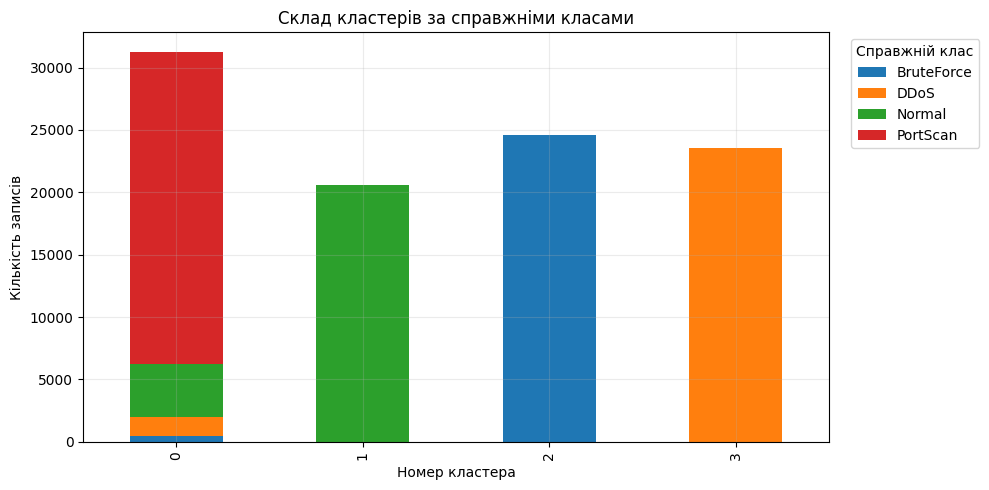

In [9]:
cluster_class_table = pd.crosstab(
    pd.Series(cluster_labels, name='Кластер'),
    pd.Series(y.values, name='Справжній клас')
)
print('Кількість об’єктів кожного класу в кластерах:')
display(cluster_class_table)

print('Частки класів усередині кожного кластера:')
display(pd.crosstab(
    pd.Series(cluster_labels, name='Кластер'),
    pd.Series(y.values, name='Справжній клас'),
    normalize='index'
).round(3))

ax = cluster_class_table.plot(kind='bar', stacked=True, figsize=(10, 5))
ax.set_title('Склад кластерів за справжніми класами')
ax.set_xlabel('Номер кластера')
ax.set_ylabel('Кількість записів')
ax.legend(title='Справжній клас', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Висновок 2:

За Silhouette Score найкращим серед перевірених значень виявилося k=4 (0,4682); графік інерції також має помітне уповільнення зменшення приблизно біля чотирьох кластерів. Фінальна модель навчалася без `attack_type`.

Таблиця спряженості показала таку структуру: кластер 1 містить лише `Normal` (20 597 записів); кластер 2 майже повністю відповідає `BruteForce` (24 598 записів і один запис `Normal`); кластер 3 містить лише `DDoS` (23 545 записів). Кластер 0 є змішаним: 25 008 `PortScan` (приблизно 80% кластера), 4 278 `Normal`, 1 532 `DDoS` та 441 `BruteForce`.

ARI = 0,8410 та NMI = 0,8551 свідчать про високу, але не повну відповідність кластерів початковим класам. Три класи відокремилися дуже добре, тоді як `PortScan` утворив переважно один кластер, до якого потрапила частина інших типів подій. Отже, кластерна структура значною мірою відображає реальні класи, але K-Means не відтворив їх один до одного. Це очікувано: алгоритм групує об'єкти за відстанями між ознаками, а не за відомими мітками.

Завдання 3: Обробка та класифікація текстових даних
Оскільки вихідний файл містить структуровані дані, створимо для кожного запису короткий текстовий опис. Числові значення перетворюються на інтервали (`very short`, `medium`, `high` тощо), що робить опис схожим на текстову характеристику мережевої події. У текст включаються тільки `duration`, `src_bytes`, `dst_bytes`, `packet_count`, `protocol` і `failed_logins`. Мітка `attack_type` зберігається окремо як target і не потрапляє в документ.
Після очищення текстів від пунктуації та стоп-слів буде побудовано WordCloud для кожного класу. Далі `TfidfVectorizer` перетворить тексти на числові вектори, а `LinearSVC` виконає класифікацію.

In [10]:
text_df = df.copy()

# Перетворення числових полів на інтервальні текстові категорії.
text_df['duration_band'] = pd.cut(
    text_df['duration'], bins=[0, 5, 15, 30, 60.01],
    labels=['very short', 'short', 'medium', 'long'], include_lowest=True
).astype(str)
text_df['src_band'] = pd.cut(
    text_df['src_bytes'], bins=[0, 500, 2000, 5000, 10000.01],
    labels=['low', 'medium', 'high', 'very high'], include_lowest=True
).astype(str)
text_df['dst_band'] = pd.cut(
    text_df['dst_bytes'], bins=[0, 200, 600, 1200, 2000.01],
    labels=['low', 'medium', 'high', 'very high'], include_lowest=True
).astype(str)
text_df['packet_band'] = pd.cut(
    text_df['packet_count'], bins=[0, 75, 200, 500, 1000.01],
    labels=['low', 'medium', 'high', 'very high'], include_lowest=True
).astype(str)
text_df['login_band'] = pd.cut(
    text_df['failed_logins'], bins=[-0.1, 0.1, 3.1, 7.1, 10.1],
    labels=['zero', 'few', 'moderate', 'many'], include_lowest=True
).astype(str)

def create_event_description(row):
    return (
        f"{row.protocol} protocol; {row.duration_band} duration; "
        f"{row.src_band} source bytes; {row.dst_band} destination bytes; "
        f"{row.packet_band} packet count; {row.login_band} failed logins."
    )

text_df['text'] = [create_event_description(row) for row in text_df.itertuples(index=False)]
text_dataset = text_df[['text', 'attack_type']].rename(columns={'attack_type': 'label'})
print('Розмір текстового набору:', text_dataset.shape)
print('\nПриклади текстових документів:')
display(text_dataset.sample(8, random_state=RANDOM_STATE))

Розмір текстового набору: (100000, 2)

Приклади текстових документів:


,text,label
75721,TCP protocol; medium duration; high source byt...,Normal
80184,UDP protocol; short duration; medium source by...,BruteForce
19864,UDP protocol; long duration; medium source byt...,Normal
76699,TCP protocol; very short duration; very high s...,DDoS
92991,UDP protocol; long duration; medium source byt...,BruteForce
76434,UDP protocol; medium duration; low source byte...,BruteForce
84004,TCP protocol; very short duration; very high s...,DDoS
80917,UDP protocol; medium duration; medium source b...,BruteForce


Очищення тексту та WordCloud:
Текст приводиться до нижнього регістру, пунктуація видаляється, а англомовні стоп-слова виключаються. Доменні слова на кшталт `protocol`, `bytes`, `packet` залишаються у тексті, оскільки описують характеристики події.

Приклад до очищення:
TCP protocol; very short duration; very high source bytes; medium destination bytes; very high packet count; zero failed logins.

Приклад після очищення:
tcp protocol short duration high source bytes medium destination bytes high packet count zero failed logins


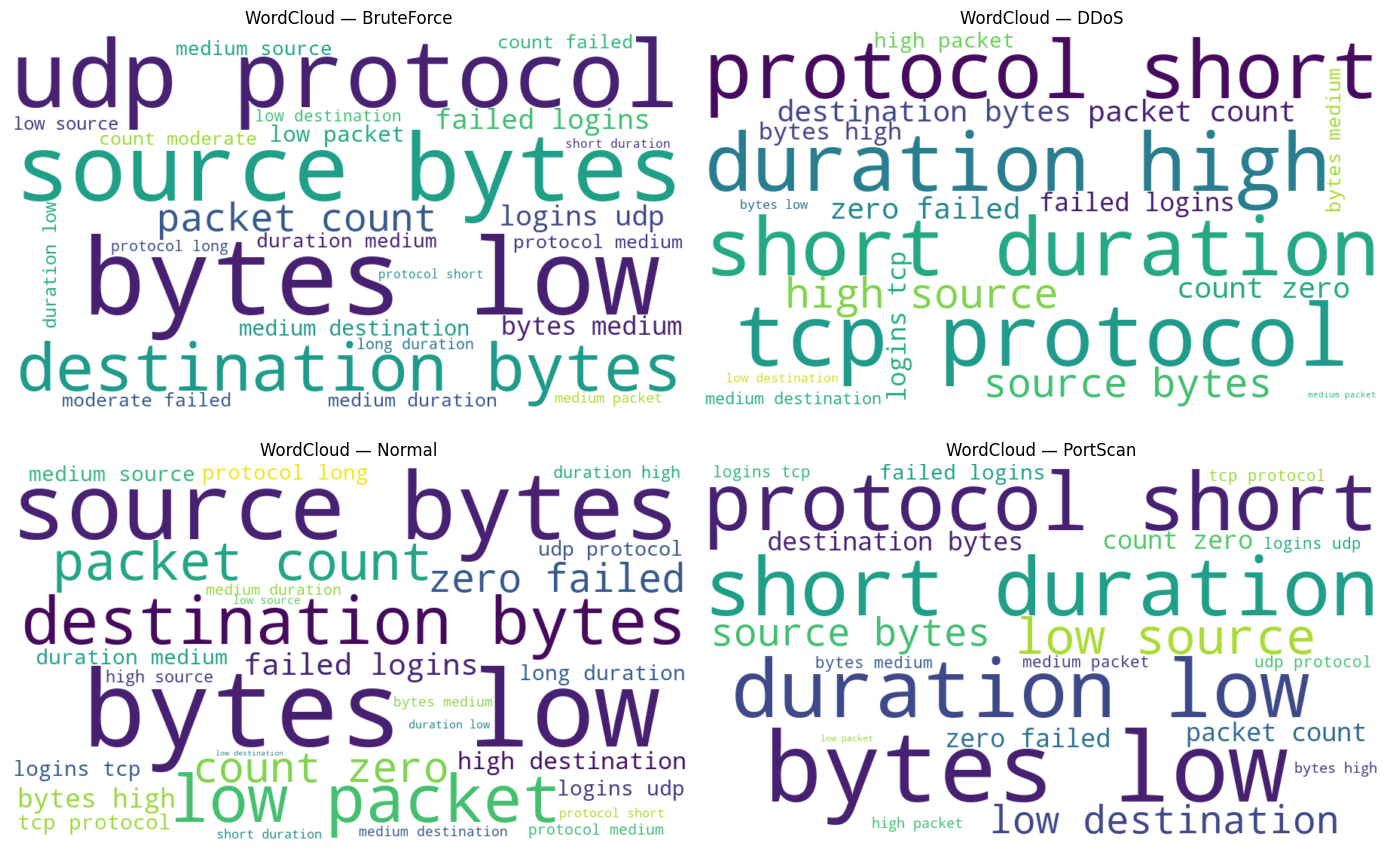

In [11]:
def clean_text(text):
    text = text.lower()
    tokens = re.findall(r'[a-z]+', text)
    tokens = [token for token in tokens if token not in ENGLISH_STOP_WORDS]
    return ' '.join(tokens)

text_dataset['clean_text'] = text_dataset['text'].apply(clean_text)
print('Приклад до очищення:')
print(text_dataset.iloc[0]['text'])
print('\nПриклад після очищення:')
print(text_dataset.iloc[0]['clean_text'])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, label in zip(axes.ravel(), sorted(text_dataset['label'].unique())):
    class_text = ' '.join(text_dataset.loc[text_dataset['label'] == label, 'clean_text'])
    cloud = WordCloud(
        width=900, height=500, background_color='white',
        max_words=35, collocations=True, random_state=RANDOM_STATE
    ).generate(class_text)
    ax.imshow(cloud, interpolation='bilinear')
    ax.set_title(f'WordCloud — {label}')
    ax.axis('off')
plt.tight_layout()
plt.show()

Висновок:
WordCloud відображає характерні ознаки подій у кожному класі. Для `BruteForce` помітні `UDP` і слова, пов'язані з невдалими спробами входу; у цьому класі протокол UDP використовується всіма записами, а кількість невдалих входів є ненульовою. Для `DDoS` характерні `TCP`, коротка тривалість, високі значення вихідного трафіку та кількості пакетів. Для `Normal` частіше трапляються довші з'єднання, більший обсяг destination bytes і низька кількість пакетів. Для `PortScan` характерні короткі з'єднання та низькі обсяги source/destination bytes.

`Normal` і `PortScan` мають приблизно рівний розподіл TCP та UDP, тому інші мережеві характеристики є важливішими для їх розрізнення. WordCloud показує частотність слів, а не причинно-наслідкові зв'язки та не формальну важливість ознак.

TF-IDF та класифікація текстів:
Дані поділяються на training та test вибірки зі збереженням пропорцій класів. `TfidfVectorizer` навчається тільки на training-текстах, щоб уникнути витоку інформації з test-вибірки. Для класифікації використовується `LinearSVC` — ефективний лінійний класифікатор для розріджених TF-IDF матриць.

TF-IDF train matrix: (80000, 50)
TF-IDF test matrix: (20000, 50)
Кількість унікальних TF-IDF ознак: 50
Час навчання LinearSVC: 3.594 с
Accuracy: 0.9997
Macro F1: 0.9997

Classification report:
              precision    recall  f1-score   support

  BruteForce       1.00      1.00      1.00      5008
        DDoS       1.00      1.00      1.00      5015
      Normal       1.00      1.00      1.00      4975
    PortScan       1.00      1.00      1.00      5002

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



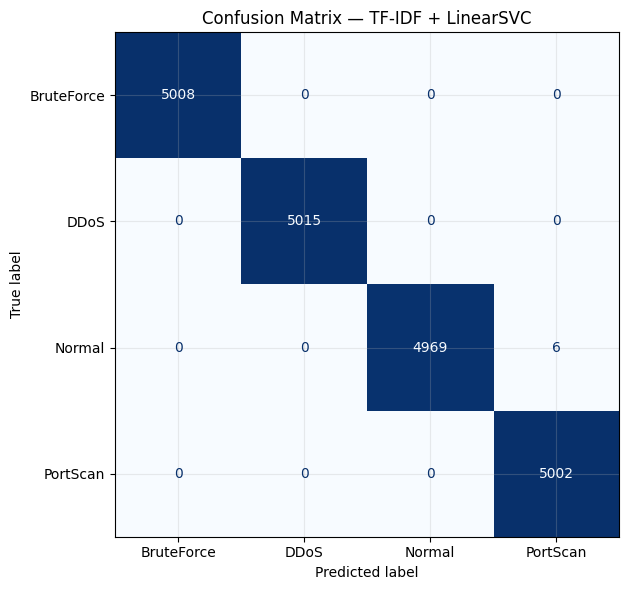

In [12]:
X_text_train, X_text_test, y_text_train, y_text_test = train_test_split(
    text_dataset['clean_text'], text_dataset['label'],
    test_size=0.20, random_state=RANDOM_STATE, stratify=text_dataset['label']
)

vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_features=10_000,
    sublinear_tf=True
)
X_tfidf_train = vectorizer.fit_transform(X_text_train)
X_tfidf_test = vectorizer.transform(X_text_test)

print('TF-IDF train matrix:', X_tfidf_train.shape)
print('TF-IDF test matrix:', X_tfidf_test.shape)
print('Кількість унікальних TF-IDF ознак:', len(vectorizer.get_feature_names_out()))

text_classifier = LinearSVC(random_state=RANDOM_STATE)
text_start = time.perf_counter()
text_classifier.fit(X_tfidf_train, y_text_train)
text_train_time = time.perf_counter() - text_start
text_predictions = text_classifier.predict(X_tfidf_test)

text_accuracy = accuracy_score(y_text_test, text_predictions)
text_macro_f1 = f1_score(y_text_test, text_predictions, average='macro')
print(f'Час навчання LinearSVC: {text_train_time:.3f} с')
print(f'Accuracy: {text_accuracy:.4f}')
print(f'Macro F1: {text_macro_f1:.4f}')
print('\nClassification report:')
print(classification_report(y_text_test, text_predictions, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
cm_text = confusion_matrix(y_text_test, text_predictions, labels=sorted(text_dataset['label'].unique()))
ConfusionMatrixDisplay(
    cm_text, display_labels=sorted(text_dataset['label'].unique())
).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Confusion Matrix — TF-IDF + LinearSVC')
plt.tight_layout()
plt.show()

Висновок по результатам текстової класифікації:

У тестовій вибірці отримано Accuracy = 0,9997 та Macro F1 = 0,9997. Це високий результат, оскільки сформовані текстові описи безпосередньо кодують ті самі мережеві характеристики, за якими у вихідному датасеті розподілені класи. У текст не додавалася назва класу, але модель отримує інформативні слова на кшталт `very short`, `very high`, `UDP` і `many`, які відображають значення predictor-ознак.

Це є наслідком роботи `TF-IDF + LinearSVC` на структурованих записах. На реальних SOC-повідомленнях або довільних текстах такої точності вже не буде.

Загальні висновки:
У роботі досліджено три напрями: зниження розмірності, кластеризацію та текстову класифікацію
Основні результати

1. Основні результати PCA
Зниження розмірності: ознак зменшено з 7 до 5 (на 28.6%). При цьому PCA зберіг 95.87% дисперсії.
Accuracy до PCA: 0.99980; після PCA: 0.99835.
Час навчання дерева: 0.1397 с до PCA та 0.3652 с після PCA - PCA суттєво не погіршив класифікацію, зменшивши при цьому кількість вимірів.
Побудовано t-SNE 2D-проєкцію для 2,400 стратифікованих записів, що дозволяє оцінити локальне групування класів.

2. Основні результати кластерного аналізу
За Silhouette Score обрано k=4; оцінка silhouette на підвибірці: 0.4673, ARI=0.8410, NMI=0.8551.
Значення ARI/NMI показують ступінь відповідності знайдених кластерів справжнім класам, але кластери не є тотожними класам і навчаються без використання target.

3. Основні результати текстової класифікації
Тексти було сформовано на основі ознак датасету; на реальних текстах оцінка має сильно відрізнятися:
TF-IDF + LinearSVC: Accuracy=0.9997, Macro F1=0.9997.